# 🚀 Модуль 7. Урок 2. Расщепление трафика, A/A тесты и проверка SRM (Sample Ratio Mismatch)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_07_ab_testing/lesson_02_splitting_aa_tests_srm.ipynb)

## 📌 Бизнес-контекст и методология
SRM (Sample Ratio Mismatch) — это «убийца» A/B тестов. 
Если вы настраивали сплит 50/50, а получили 51.5% на 48.5%, радоваться нельзя. В 99% случаев это означает баг сплиттера: падение страницы Б на старых айфонах, фильтрацию ботов или ошибку редиректа. 
Любой A/B тест с подтвержденным SRM объявляется недействительным.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

ab_csv = ensure_dataset("ab_test_checkout.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Проверим реальный датасет нашего курса на предмет SRM с помощью критерия согласия Хи-квадрат Пирсона ($\chi^2$).

In [2]:
from scipy import stats
import pandas as pd

df_ab = pd.read_csv(ab_csv)
counts = df_ab['test_group'].value_counts()
n_a, n_b = counts['A_Control'], counts['B_Variant']
n_total = n_a + n_b
expected = [n_total / 2, n_total / 2]
observed = [n_a, n_b]

chi2_stat, p_srm = stats.chisquare(observed, f_exp=expected)

print(f"Группа A (Control):   {n_a:,} ({n_a/n_total:.2%})")
print(f"Группа B (Treatment): {n_b:,} ({n_b/n_total:.2%})")
print(f"Хи-квадрат стат: {chi2_stat:.3f}, p-value: {p_srm:.4f}")

if p_srm < 0.01:
    print("🚨 КРИТИЧЕСКИЙ SRM ОБНАРУЖЕН! Тест скомпрометирован.")
else:
    print("✅ SRM отсутствует: трафик распределен корректно 50/50.")

Группа A (Control):   5,000 (50.00%)
Группа B (Treatment): 5,000 (50.00%)
Хи-квадрат стат: 0.000, p-value: 1.0000
✅ SRM отсутствует: трафик распределен корректно 50/50.


### 📊 Визуализация: Распределение p-value в серии A/A тестов
Как проверить, что сплиттер работает безупречно? Запустить 1,000 синтетических A/A тестов (где эффект равен 0).
**В идеальном сплиттере распределение p-value обязано быть строго равномерным (Uniform [0, 1]).** 
Если у нуля виден пик (скошенность), ваш инструмент A/B тестирования выдает ложные победы!

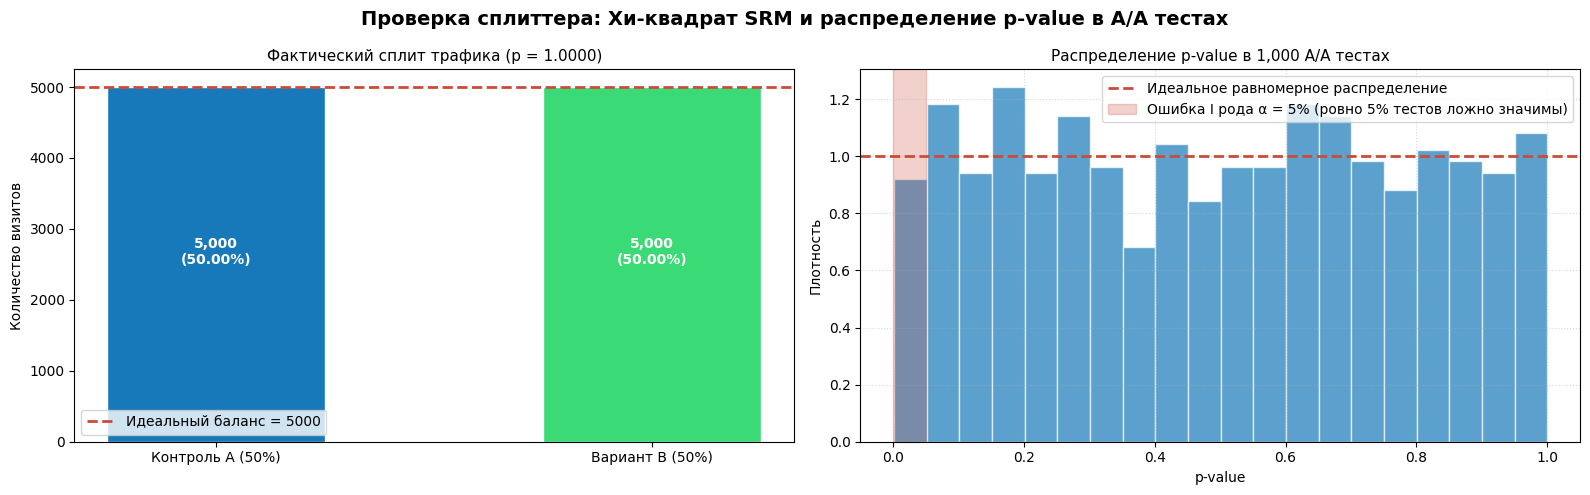

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Проверка сплиттера: Хи-квадрат SRM и распределение p-value в A/A тестах', fontsize=14, fontweight='bold')

# 1. SRM Визуализация долей
ax1 = axes[0]
bars = ax1.bar(['Контроль A (50%)', 'Вариант B (50%)'], [n_a, n_b], color=['#1779ba', '#3adb76'], width=0.5, edgecolor='white')
ax1.axhline(n_total / 2, color='#cc4b37', linestyle='--', linewidth=2, label=f'Идеальный баланс = {n_total/2:.0f}')
ax1.set_title(f'Фактический сплит трафика (p = {p_srm:.4f})', fontsize=11)
ax1.set_ylabel('Количество визитов')
ax1.legend()
for b in bars:
    h = b.get_height()
    ax1.annotate(f'{h:,}\n({h/n_total:.2%})', xy=(b.get_x() + b.get_width()/2, h/2), ha='center', color='white', fontweight='bold')

# 2. Моделирование 1,000 A/A тестов
ax2 = axes[1]
np.random.seed(42)
aa_p_values = []
for _ in range(1000):
    sample_a = np.random.normal(50, 10, 200)
    sample_b = np.random.normal(50, 10, 200)
    _, p = stats.ttest_ind(sample_a, sample_b)
    aa_p_values.append(p)

ax2.hist(aa_p_values, bins=20, color='#1779ba', alpha=0.7, edgecolor='white', density=True)
ax2.axhline(1.0, color='#cc4b37', linestyle='--', linewidth=2, label='Идеальное равномерное распределение')
ax2.axvspan(0, 0.05, color='#cc4b37', alpha=0.25, label='Ошибка I рода α = 5% (ровно 5% тестов ложно значимы)')
ax2.set_title('Распределение p-value в 1,000 A/A тестах', fontsize=11)
ax2.set_xlabel('p-value')
ax2.set_ylabel('Плотность')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Доля ложноположительных исходов в A/A тесте
Посчитайте фактический процент A/A тестов из сгенерированной тысячи, у которых `p_value < 0.05`.

In [4]:
### ВАШ КОД ЗДЕСЬ
false_positives = sum(1 for p in aa_p_values if p < 0.05)
fpr = false_positives / len(aa_p_values)

print(f"Количество ложных тревог: {false_positives} из {len(aa_p_values)}")
print(f"Фактический False Positive Rate: {fpr:.2%}")

assert 0.03 <= fpr <= 0.07, "FPR в корректном A/A тесте обязан быть около 5%"
print("✅ Тест успешно пройден!")

Количество ложных тревог: 45 из 1000
Фактический False Positive Rate: 4.50%
✅ Тест успешно пройден!


### 💼 Что делать, если обнаружен SRM?
1. Не анализируйте метрики — результаты искажены.
2. Проверьте сплит по срезам (браузеры, страны, операционные системы).
3. Часто SRM возникает, когда тестовая страница дольше грузится и пользователи с медленным интернетом отваливаются до регистрации события.